# PubChem Database Chemical Information - Extract, Analyze, Plot & Visualize.

To extract, analyze, and plot chemical information from the PubChem database directly in Google Colab, you can use pubchempy to fetch compound details, rdkit to render 2D molecular structures, and standard libraries like pandas and seaborn to handle tables and visualizations.

---

Prof. Jeff Yarger

jyarger@proton.me

## Step 1: Install & Import Required Toolkits

In [1]:
# Install specialized cheminformatics libraries
!pip install pubchempy rdkit -q

import pubchempy as pcp
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from rdkit import Chem
from rdkit.Chem import Draw
from rdkit.Chem import PandasTools

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.8/31.8 MB 35.6 MB/s eta 0:00:00


## Step 2: Fetch Data and Build a Pandas Table

In [2]:
# Define your target list of molecules
molecule_names = ["Aspirin", "Caffeine", "Ibuprofen", "Acetaminophen", "Nicotine", "Metformin"]

data_list = []

for name in molecule_names:
    try:
        # Search PubChem by name and take the top match
        compounds = pcp.get_compounds(name, 'name')
        if compounds:
            comp = compounds[0]
            data_list.append({
                "Name": name,
                "CID": comp.cid,
                "Formula": comp.molecular_formula,
                "MW": comp.molecular_weight,
                "LogP": comp.xlogp,
                "TPSA": comp.tpsa,
                "H_Donors": comp.h_bond_donor_count,
                "H_Acceptors": comp.h_bond_acceptor_count,
                "SMILES": comp.isomeric_smiles
            })
    except Exception as e:
        print(f"Could not retrieve {name}: {e}")

# Create the Pandas Dataframe
df = pd.DataFrame(data_list)

# Display the interactive dataframe
df

/tmp/ipykernel_1805/1716077216.py:21: PubChemPyDeprecationWarning: isomeric_smiles is deprecated: Use smiles instead
  "SMILES": comp.isomeric_smiles


,Name,CID,Formula,MW,LogP,TPSA,H_Donors,H_Acceptors,SMILES
0,Aspirin,2244,C9H8O4,180.16,1.2,63.6,1,4,CC(=O)OC1=CC=CC=C1C(=O)O
1,Caffeine,2519,C8H10N4O2,194.19,-0.1,58.4,0,3,CN1C=NC2=C1C(=O)N(C(=O)N2C)C
2,Ibuprofen,3672,C13H18O2,206.28,3.5,37.3,1,2,CC(C)CC1=CC=C(C=C1)C(C)C(=O)O
3,Acetaminophen,1983,C8H9NO2,151.16,0.5,49.3,2,2,CC(=O)NC1=CC=C(C=C1)O
4,Nicotine,89594,C10H14N2,162.23,1.2,16.1,0,2,CN1CCC[C@H]1C2=CN=CC=C2
5,Metformin,4091,C4H11N5,129.16,-1.3,91.5,3,1,CN(C)C(=N)N=C(N)N


## Step 3: Embed 2D Molecular Structures in the Table

In [3]:
# Generate structural column from SMILES notation
PandasTools.AddMoleculeColumnToFrame(df, smilesCol='SMILES', molCol='Structure')

# Render the table with visual molecule structures
df[['Name', 'Formula', 'MW', 'LogP', 'Structure']]


,Name,Formula,MW,LogP,Structure
0,Aspirin,C9H8O4,180.16,1.2,<rdkit.Chem.rdchem.Mol object at 0x7ce35227a880>
1,Caffeine,C8H10N4O2,194.19,-0.1,<rdkit.Chem.rdchem.Mol object at 0x7ce35227aa40>
2,Ibuprofen,C13H18O2,206.28,3.5,<rdkit.Chem.rdchem.Mol object at 0x7ce35227a7a0>
3,Acetaminophen,C8H9NO2,151.16,0.5,<rdkit.Chem.rdchem.Mol object at 0x7ce35227a8f0>
4,Nicotine,C10H14N2,162.23,1.2,<rdkit.Chem.rdchem.Mol object at 0x7ce35227a9d0>
5,Metformin,C4H11N5,129.16,-1.3,<rdkit.Chem.rdchem.Mol object at 0x7ce35227aab0>


## Step 4: Map & Visualize the Chemical Space (Plots)

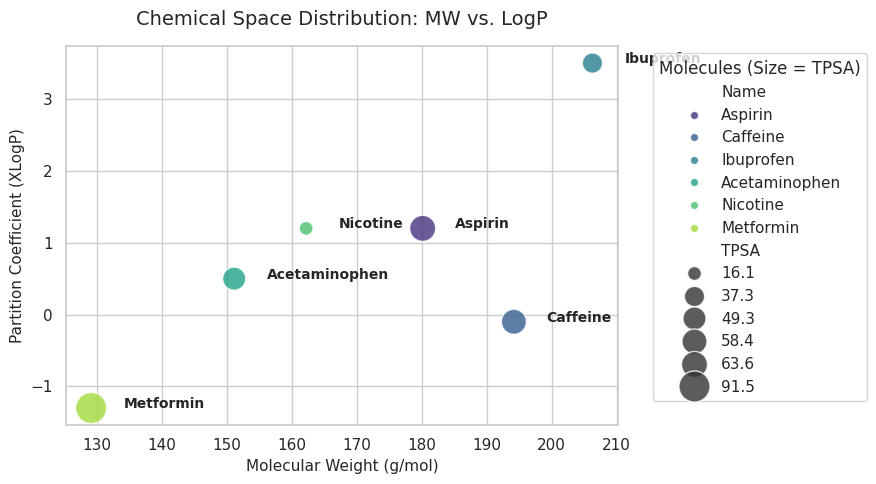

In [4]:
plt.figure(figsize=(9, 5))
sns.set_theme(style="whitegrid")

# Create a scatter plot representing Lipinski-like metrics
scatter = sns.scatterplot(
    data=df,
    x="MW",
    y="LogP",
    hue="Name",
    size="TPSA",
    sizes=(100, 500),
    palette="viridis",
    alpha=0.8
)

# Label every point with its drug name
for idx, row in df.iterrows():
    plt.text(row['MW'] + 5, row['LogP'], row['Name'], fontsize=10, weight='semibold')

plt.title("Chemical Space Distribution: MW vs. LogP", fontsize=14, pad=15)
plt.xlabel("Molecular Weight (g/mol)", fontsize=11)
plt.ylabel("Partition Coefficient (XLogP)", fontsize=11)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title="Molecules (Size = TPSA)")
plt.tight_layout()
plt.show()


## Step 5: Draw a Grid Image of Structures

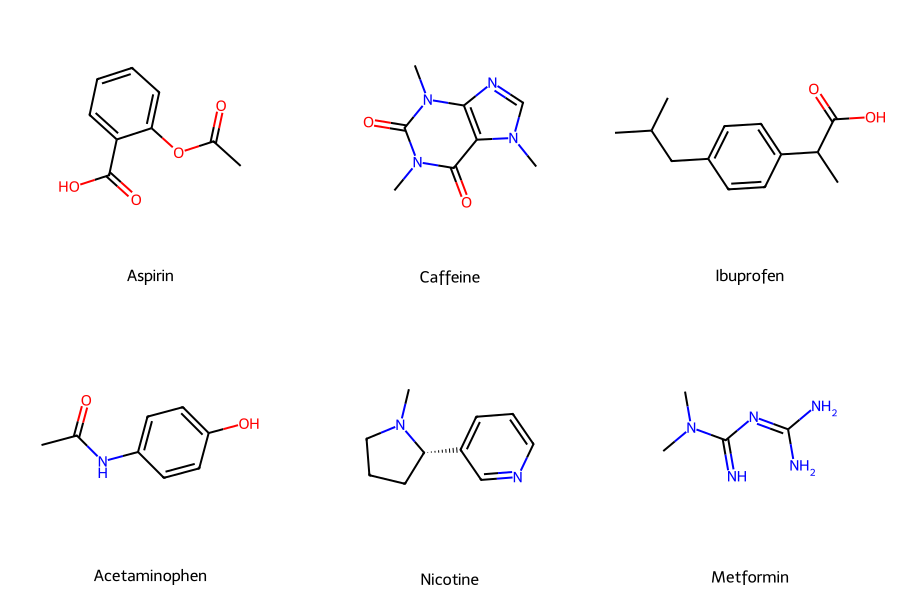

In [5]:
# Extract RDKit mol objects
mols = [Chem.MolFromSmiles(s) for s in df['SMILES']]
labels = df['Name'].tolist()

# Draw a grid layout (3 columns)
img = Draw.MolsToGridImage(mols, legends=labels, molsPerRow=3, subImgSize=(300, 300))
img


## Step 6: Filter by Lipinski's Rule of 5

This block evaluates whether each molecule complies with the drug-likeness rules. It dynamically calculates compliance criteria and appends a boolean column flag to your existing table.

In [6]:
def check_lipinski(row):
    """Evaluates Lipinski's Rule of 5 parameters."""
    mw_ok = row['MW'] <= 500
    logp_ok = pd.isna(row['LogP']) or row['LogP'] <= 5
    donors_ok = row['H_Donors'] <= 5
    acceptors_ok = row['H_Acceptors'] <= 10

    # Track individual failures if needed
    violations = sum([not mw_ok, not logp_ok, not donors_ok, not acceptors_ok])

    return violations <= 1  # True if passes (allows max 1 violation)

# Apply filter across the dataset
df['Lipinski_Pass'] = df.apply(check_lipinski, axis=1)

# Format background colors to highlight passes
df[['Name', 'MW', 'LogP', 'H_Donors', 'H_Acceptors', 'Lipinski_Pass']].style.map(
    lambda val: 'background-color: #d4edda' if val is True else ('background-color: #f8d7da' if val is False else ''),
    subset=['Lipinski_Pass']
)


,Name,MW,LogP,H_Donors,H_Acceptors,Lipinski_Pass
0,Aspirin,180.160000,1.200000,1,4,True
1,Caffeine,194.190000,-0.100000,0,3,True
2,Ibuprofen,206.280000,3.500000,1,2,True
3,Acetaminophen,151.160000,0.500000,2,2,True
4,Nicotine,162.230000,1.200000,0,2,True
5,Metformin,129.160000,-1.300000,3,1,True


## Step 7: Substructure Similarity Search

You can use SMILES or SMARTS patterns to screen your library for specific functional groups. In this example, we will search for compounds that contain a benzene ring or an ester functional group.

In [7]:
# 1. Define your query substructure pattern (e.g., Benzene Ring)
# You can use a SMILES string "c1ccccc1" or SMARTS code
query_smiles = "c1ccccc1"
query_mol = Chem.MolFromSmiles(query_smiles)

print(f"Searching dataset for substructure match: {query_smiles}")

# 2. Function to evaluate alignment match
def has_substructure(smiles_str, query):
    target_mol = Chem.MolFromSmiles(smiles_str)
    if target_mol and query:
        return target_mol.HasSubstructMatch(query)
    return False

# 3. Add verification flag to dataframe
df['Substructure_Match'] = df['SMILES'].apply(lambda x: has_substructure(x, query_mol))

# 4. Filter data to showcase isolated positive results
matching_compounds = df[df['Substructure_Match'] == True]
print(f"Found {len(matching_compounds)} matching molecules.")
matching_compounds[['Name', 'Formula', 'SMILES']]


Searching dataset for substructure match: c1ccccc1
Found 3 matching molecules.


,Name,Formula,SMILES
0,Aspirin,C9H8O4,CC(=O)OC1=CC=CC=C1C(=O)O
2,Ibuprofen,C13H18O2,CC(C)CC1=CC=C(C=C1)C(C)C(=O)O
3,Acetaminophen,C8H9NO2,CC(=O)NC1=CC=C(C=C1)O


## Step 8: Visualize Substructure Alignment Matches

This block highlights the matching functional core in bold red color layers directly overlaying the 2D molecule coordinate maps.

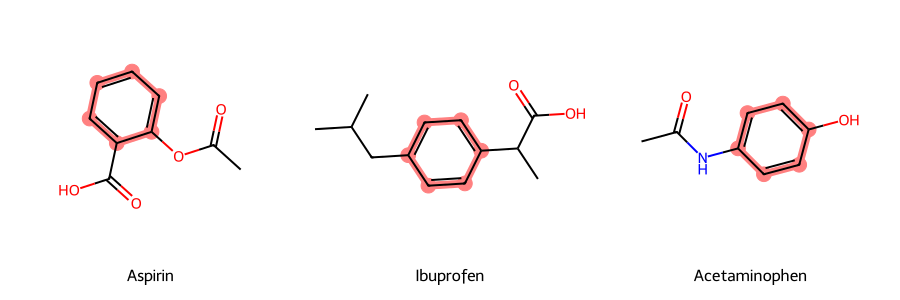

In [8]:
# Isolate matches for rendering
matching_mols = [Chem.MolFromSmiles(s) for s in matching_compounds['SMILES']]
matching_names = matching_compounds['Name'].tolist()

# Identify atoms aligned with the core structural query pattern
highlight_atoms_list = []
for mol in matching_mols:
    matches = mol.GetSubstructMatch(query_mol)
    highlight_atoms_list.append(matches)

# Render aligned map matrix
Draw.MolsToGridImage(
    matching_mols,
    legends=matching_names,
    molsPerRow=3,
    subImgSize=(300, 300),
    highlightAtomLists=highlight_atoms_list
)


# Interactive Screening in Colab

This script utilizes Colab Form Fields (#@param) and IPython Widgets to let you dynamically add new molecules by name, input custom SMILES strings, select a functional group filter, and view the rendered evaluation on the fly.

🔄 Querying PubChem API...


/tmp/ipykernel_1805/1348855535.py:41: PubChemPyDeprecationWarning: isomeric_smiles is deprecated: Use smiles instead
  "SMILES": comp.isomeric_smiles



📋 DATASET SUMMARY & LIPINSKI COMPLIANCE:


,Name,MW,LogP,H_Donors,H_Acceptors,Lipinski_Pass
0,Aspirin,180.160000,1.200000,1,4,True
1,Caffeine,194.190000,-0.100000,0,3,True
2,Ibuprofen,206.280000,3.500000,1,2,True
3,Nicotine,162.230000,1.200000,0,2,True
4,Paracetamol,151.160000,0.500000,2,2,True
5,Custom Aspirin Entry,180.160000,1.310000,1,3,True



🔬 SUBSTRUCTURE HIGHLIGHTING MAP (Pattern: 'c1ccccc1'):


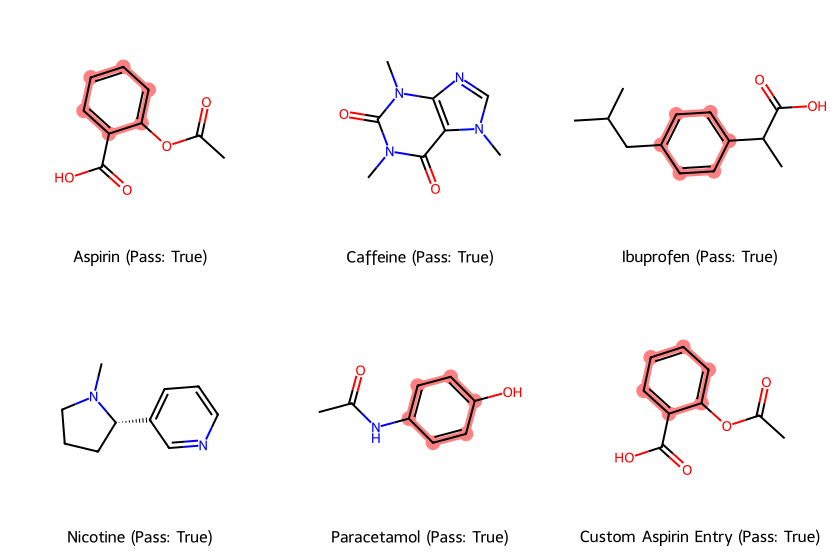

In [9]:
#@title 🧪 PubChem Interactive Molecule Analyzer & Filter { display-mode: "form" }
#@markdown Run this cell to generate the user interface dashboard. You can modify inputs on the right side dynamically.

import pubchempy as pcp
import pandas as pd
from rdkit import Chem
from rdkit.Chem import Draw
from rdkit.Chem import PandasTools
import ipywidgets as widgets
from IPython.display import display, HTML, clear_output

# --- FORM PARAMS ---
#@markdown ### 1. Add Custom Data to Dataset
add_by_name = "Aspirin, Caffeine, Ibuprofen, Nicotine, Paracetamol" #@param {type:"string"}
custom_smiles = "CC(=O)Oc1ccccc1C(=O)O" #@param {type:"string"}
smiles_label = "Custom Aspirin Entry" #@param {type:"string"}

#@markdown ### 2. Query Substructure Screening
#@markdown Select or type a SMARTS/SMILES pattern to visually highlight in matching molecules.
functional_group = "Benzene Ring (c1ccccc1)" #@param ["Benzene Ring (c1ccccc1)", "Carboxylic Acid (C(=O)O)", "Amine (N)", "Ester (C(=O)OC)"]
custom_pattern = "" #@param {type:"string"}

# --- LOGIC RUNNER ---
def run_interactive_pipeline():
    clear_output(wait=True)

    # Process target molecule names
    names_list = [n.strip() for n in add_by_name.split(",") if n.strip()]
    data_list = []

    # 1. Fetch from PubChem
    print("🔄 Querying PubChem API...")
    for name in names_list:
        try:
            compounds = pcp.get_compounds(name, 'name')
            if compounds:
                comp = compounds[0]
                data_list.append({
                    "Name": name, "MW": comp.molecular_weight, "LogP": comp.xlogp,
                    "H_Donors": comp.h_bond_donor_count, "H_Acceptors": comp.h_bond_acceptor_count,
                    "SMILES": comp.isomeric_smiles
                })
        except Exception:
            pass

    # 2. Append Custom SMILES if provided
    if custom_smiles:
        try:
            custom_mol = Chem.MolFromSmiles(custom_smiles)
            if custom_mol:
                from rdkit.Chem import Descriptors
                data_list.append({
                    "Name": smiles_label if smiles_label else "Custom Input",
                    "MW": round(Descriptors.MolWt(custom_mol), 2),
                    "LogP": round(Descriptors.MolLogP(custom_mol), 2),
                    "H_Donors": Descriptors.NumHDonors(custom_mol),
                    "H_Acceptors": Descriptors.NumHAcceptors(custom_mol),
                    "SMILES": custom_smiles
                })
        except Exception as e:
            print(f"⚠️ Could not parse custom SMILES: {e}")

    if not data_list:
        print("❌ No valid molecules loaded. Please verify inputs.")
        return

    df = pd.DataFrame(data_list)

    # 3. Apply Lipinski Filter
    df['Lipinski_Pass'] = df.apply(
        lambda r: sum([not (r['MW']<=500), not (pd.isna(r['LogP']) or r['LogP']<=5), not (r['H_Donors']<=5), not (r['H_Acceptors']<=10)]) <= 1,
        axis=1
    )

    # 4. Determine Query Substructure Pattern
    pattern_string = custom_pattern if custom_pattern.strip() else functional_group.split("(")[-1].replace(")", "")
    query_pattern = Chem.MolFromSmarts(pattern_string) or Chem.MolFromSmiles(pattern_string)

    # 5. Display Lipinski Compliance Table
    print("\n📋 DATASET SUMMARY & LIPINSKI COMPLIANCE:")
    styled_df = df[['Name', 'MW', 'LogP', 'H_Donors', 'H_Acceptors', 'Lipinski_Pass']].style.map(
        lambda val: 'background-color: #e2f0d9; font-weight: bold;' if val is True else ('background-color: #fce4d6;' if val is False else ''),
        subset=['Lipinski_Pass']
    )
    display(styled_df)

    # 6. Render Structural Imagery with Matching Targets Highlighted
    print(f"\n🔬 SUBSTRUCTURE HIGHLIGHTING MAP (Pattern: '{pattern_string}'):")
    mols = [Chem.MolFromSmiles(s) for s in df['SMILES']]
    legends = [f"{row['Name']} (Pass: {row['Lipinski_Pass']})" for _, row in df.iterrows()]

    highlight_atoms = []
    for mol in mols:
        if mol and query_pattern:
            match = mol.GetSubstructMatch(query_pattern)
            highlight_atoms.append(match if match else [])
        else:
            highlight_atoms.append([])

    grid_img = Draw.MolsToGridImage(
        mols, legends=legends, molsPerRow=3, subImgSize=(280, 280),
        highlightAtomLists=highlight_atoms
    )
    display(grid_img)

run_interactive_pipeline()
